In [1]:
from pyspark.sql import SparkSession

# spark = SparkSession.builder.appName("FraudDetectionProject").master("local[*]").getOrCreate()

spark = SparkSession.builder \
    .appName("FraudDetection") \
    .master("local[*]") \
    .config("spark.executor.memory", "4g") \
    .config("spark.driver.memory", "4g") \
    .config("spark.serializer", "org.apache.spark.serializer.KryoSerializer") \
    .config("spark.kryoserializer.buffer.max", "512m") \
    .getOrCreate()

# Load CSV file
df = spark.read.csv("Fraud.csv", header=True, inferSchema=True)
df.printSchema()

total_num_of_rows = df.count()



root
 |-- step: integer (nullable = true)
 |-- type: string (nullable = true)
 |-- amount: double (nullable = true)
 |-- nameOrig: string (nullable = true)
 |-- oldbalanceOrg: double (nullable = true)
 |-- newbalanceOrig: double (nullable = true)
 |-- nameDest: string (nullable = true)
 |-- oldbalanceDest: double (nullable = true)
 |-- newbalanceDest: double (nullable = true)
 |-- isFraud: integer (nullable = true)
 |-- isFlaggedFraud: integer (nullable = true)



In [2]:
# Replace nulls with 0 for balances (merchant-related)
df = df.fillna({
    "oldbalanceDest": 0.0,
    "newbalanceDest": 0.0
})

# Optional: filter out illogical balance transitions
df = df.filter((df.oldbalanceOrg >= 0) & (df.newbalanceOrig >= 0))


In [3]:
df.show()

+----+--------+---------+-----------+-------------+--------------+-----------+--------------+--------------+-------+--------------+
|step|    type|   amount|   nameOrig|oldbalanceOrg|newbalanceOrig|   nameDest|oldbalanceDest|newbalanceDest|isFraud|isFlaggedFraud|
+----+--------+---------+-----------+-------------+--------------+-----------+--------------+--------------+-------+--------------+
|   1| PAYMENT|  9839.64|C1231006815|     170136.0|     160296.36|M1979787155|           0.0|           0.0|      0|             0|
|   1| PAYMENT|  1864.28|C1666544295|      21249.0|      19384.72|M2044282225|           0.0|           0.0|      0|             0|
|   1|TRANSFER|    181.0|C1305486145|        181.0|           0.0| C553264065|           0.0|           0.0|      1|             0|
|   1|CASH_OUT|    181.0| C840083671|        181.0|           0.0|  C38997010|       21182.0|           0.0|      1|             0|
|   1| PAYMENT| 11668.14|C2048537720|      41554.0|      29885.86|M123070170

In [4]:
from pyspark.sql.functions import when,col
#Is to merchant feature
df = df.withColumn("is_to_merchant", when(col("nameDest").startswith("M"), 1).otherwise(0))

df.groupBy("type").agg(
    {"isFraud": "sum", "*": "count"}
).withColumnRenamed("sum(isFraud)", "fraud_count") \
 .withColumnRenamed("count(1)", "total_count") \
 .withColumn("fraud_rate", col("fraud_count") / col("total_count")) \
 .show()
 #Transfer and Cash-out transaction types are of high risk so add it as a feature
df = df.withColumn("is_high_risk_type", when(col("type").isin("TRANSFER", "CASH_OUT"), 1).otherwise(0))
df.show(5, truncate=False)


+--------+-----------+-----------+--------------------+
|    type|fraud_count|total_count|          fraud_rate|
+--------+-----------+-----------+--------------------+
|TRANSFER|       4097|     532909|0.007687991758442811|
| CASH_IN|          0|    1399284|                 0.0|
|CASH_OUT|       4116|    2237500|0.001839553072625...|
| PAYMENT|          0|    2151495|                 0.0|
|   DEBIT|          0|      41432|                 0.0|
+--------+-----------+-----------+--------------------+

+----+--------+--------+-----------+-------------+--------------+-----------+--------------+--------------+-------+--------------+--------------+-----------------+
|step|type    |amount  |nameOrig   |oldbalanceOrg|newbalanceOrig|nameDest   |oldbalanceDest|newbalanceDest|isFraud|isFlaggedFraud|is_to_merchant|is_high_risk_type|
+----+--------+--------+-----------+-------------+--------------+-----------+--------------+--------------+-------+--------------+--------------+-----------------+
|1 

In [5]:
df.show(5, truncate=False)

+----+--------+--------+-----------+-------------+--------------+-----------+--------------+--------------+-------+--------------+--------------+-----------------+
|step|type    |amount  |nameOrig   |oldbalanceOrg|newbalanceOrig|nameDest   |oldbalanceDest|newbalanceDest|isFraud|isFlaggedFraud|is_to_merchant|is_high_risk_type|
+----+--------+--------+-----------+-------------+--------------+-----------+--------------+--------------+-------+--------------+--------------+-----------------+
|1   |PAYMENT |9839.64 |C1231006815|170136.0     |160296.36     |M1979787155|0.0           |0.0           |0      |0             |1             |0                |
|1   |PAYMENT |1864.28 |C1666544295|21249.0      |19384.72      |M2044282225|0.0           |0.0           |0      |0             |1             |0                |
|1   |TRANSFER|181.0   |C1305486145|181.0        |0.0           |C553264065 |0.0           |0.0           |1      |0             |0             |1                |
|1   |CASH_OUT|1

In [6]:
#Feature Engineering
#Engeineer New Features
from pyspark.sql.functions import col
#Balance Consistency
df = df \
    .withColumn("sender_diff", col("newbalanceOrig") - col("oldbalanceOrg")) \
    .withColumn("receiver_diff", col("newbalanceDest") - col("oldbalanceDest"))
df = df \
    .withColumn("sender_balance_error", (col("oldbalanceOrg") - col("newbalanceOrig")) - col("amount")) \
    .withColumn("receiver_balance_error", (col("newbalanceDest") - col("oldbalanceDest")) - col("amount"))
df.show(5, truncate=False)

+----+--------+--------+-----------+-------------+--------------+-----------+--------------+--------------+-------+--------------+--------------+-----------------+-------------------+-------------+-----------------------+----------------------+
|step|type    |amount  |nameOrig   |oldbalanceOrg|newbalanceOrig|nameDest   |oldbalanceDest|newbalanceDest|isFraud|isFlaggedFraud|is_to_merchant|is_high_risk_type|sender_diff        |receiver_diff|sender_balance_error   |receiver_balance_error|
+----+--------+--------+-----------+-------------+--------------+-----------+--------------+--------------+-------+--------------+--------------+-----------------+-------------------+-------------+-----------------------+----------------------+
|1   |PAYMENT |9839.64 |C1231006815|170136.0     |160296.36     |M1979787155|0.0           |0.0           |0      |0             |1             |0                |-9839.640000000014 |0.0          |1.4551915228366852E-11 |-9839.64              |
|1   |PAYMENT |1864.

In [7]:
# Count transactions where sender and receiver are the same account
from pyspark.sql.functions import col, count, when, expr

# Get the count of same-account transactions
same_account_count = df.filter(col("nameOrig") == col("nameDest")).count()

# Calculate percentage of total
total_transactions = df.count()
same_account_percent = (same_account_count / total_transactions) * 100

print(f"Same account transactions: {same_account_count:,}")
print(f"Percentage of same account transactions: {same_account_percent:.2f}%")

Same account transactions: 0
Percentage of same account transactions: 0.00%


In [8]:
"""
# ======================================
#          GRAPH CALCULATIONS
# ======================================

Graph-based analysis for identifying complex fraud patterns in transaction networks.
"""

'\n# ======================================\n#          GRAPH CALCULATIONS\n# ======================================\n\nGraph-based analysis for identifying complex fraud patterns in transaction networks.\n'

In [9]:
# Check if destination accounts also appear as originators elsewhere
from pyspark.sql.functions import col

# Get distinct originator accounts with renamed column
origin_accounts = df.select(col("nameOrig").alias("orig_account_id")).distinct()

# Join with clear column naming - removed broadcast hint to avoid memory issues
df = df.join(
    origin_accounts,
    df["nameDest"] == origin_accounts["orig_account_id"],
    "left_outer"
).withColumn(
    "dest_appears_as_origin", 
    col("orig_account_id").isNotNull().cast("int")
)

# Drop the temporary column
df = df.drop("orig_account_id")

# Check distribution of this feature
df.groupBy("dest_appears_as_origin", "isFraud") \
    .count() \
    .orderBy("dest_appears_as_origin", "isFraud") \
    .show()

+----------------------+-------+-------+
|dest_appears_as_origin|isFraud|  count|
+----------------------+-------+-------+
|                     0|      0|6341117|
|                     0|      1|   8195|
|                     1|      0|  13290|
|                     1|      1|     18|
+----------------------+-------+-------+



In [10]:
print(f"Spark version: {spark.version}")

Spark version: 3.5.5


In [11]:
# Create vertices (accounts)
from graphframes import GraphFrame
vertices = df.select(col("nameOrig").alias("id")).union(df.select(col("nameDest").alias("id"))).distinct()

# Create edges (transactions)
edges = df.select(
    col("nameOrig").alias("src"),
    col("nameDest").alias("dst"),
    "amount", "type", "isFraud"
)

# Build the graph
g = GraphFrame(vertices, edges)

c:\Users\Ali\AppData\Local\Programs\Python\Python39\lib\site-packages\pyspark\sql\dataframe.py:168: UserWarning: DataFrame.sql_ctx is an internal property, and will be removed in future releases. Use DataFrame.sparkSession instead.
  warnings.warn(


In [12]:
# Print graph statistics
print(f"Total vertices: {g.vertices.count()}")
print(f"Total edges: {g.edges.count()}")

# View vertex degree distribution
g.degrees.orderBy("degree", ascending=False).show(10)

Total vertices: 9073900
Total edges: 6362620


c:\Users\Ali\AppData\Local\Programs\Python\Python39\lib\site-packages\pyspark\sql\dataframe.py:147: UserWarning: DataFrame constructor is internal. Do not directly use it.
  warnings.warn("DataFrame constructor is internal. Do not directly use it.")


+-----------+------+
|         id|degree|
+-----------+------+
|C1286084959|   113|
| C985934102|   109|
| C665576141|   105|
|C2083562754|   102|
| C248609774|   101|
|C1590550415|   101|
|C1789550256|    99|
| C451111351|    99|
|C1360767589|    98|
|C1023714065|    97|
+-----------+------+
only showing top 10 rows



c:\Users\Ali\AppData\Local\Programs\Python\Python39\lib\site-packages\pyspark\sql\dataframe.py:147: UserWarning: DataFrame constructor is internal. Do not directly use it.
  warnings.warn("DataFrame constructor is internal. Do not directly use it.")


Vertex C1286084959: 0 outgoing, 5 incoming connections
Vertex C985934102: 0 outgoing, 5 incoming connections
Vertex C665576141: 0 outgoing, 5 incoming connections
Vertex C2083562754: 0 outgoing, 5 incoming connections
Vertex C248609774: 0 outgoing, 5 incoming connections
Vertex C1590550415: 0 outgoing, 5 incoming connections
Vertex C1789550256: 0 outgoing, 5 incoming connections
Vertex C451111351: 0 outgoing, 5 incoming connections
Vertex C1360767589: 0 outgoing, 5 incoming connections
Vertex C1023714065: 0 outgoing, 5 incoming connections
Selected center vertex: C1286084959
Found 15 neighbors
Number of edges between these vertices: 15


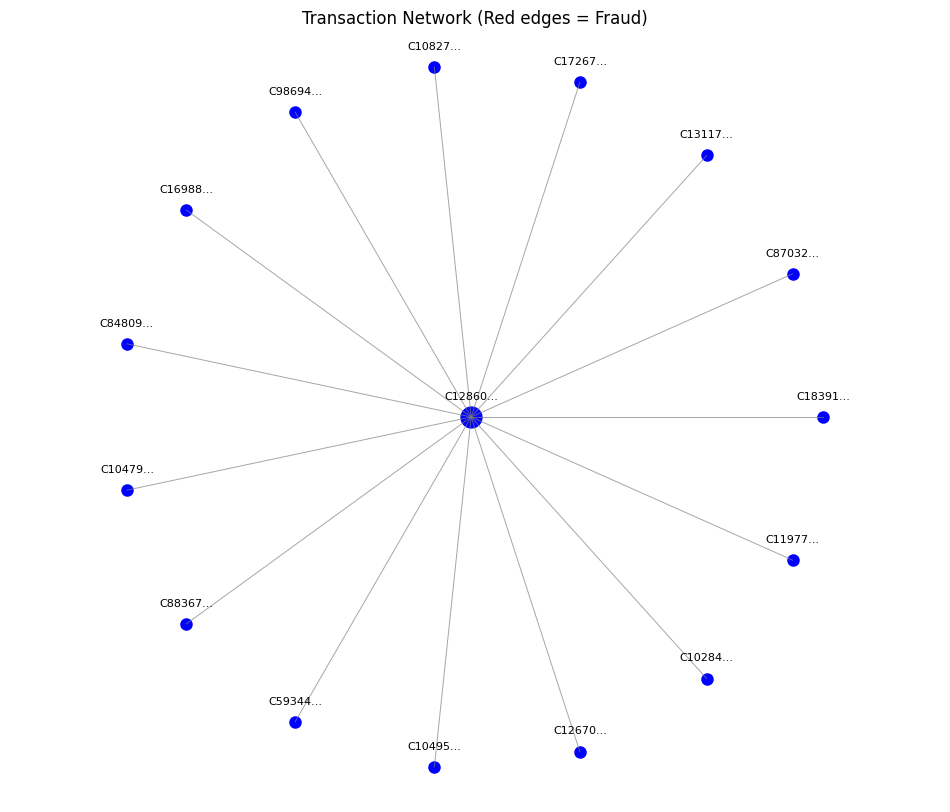

In [13]:
# Better graph visualization with guaranteed edges
from pyspark.sql.functions import col
import matplotlib.pyplot as plt
import math

# Find a vertex that has BOTH incoming and outgoing connections
# Get top 10 high-degree vertices to try
top_vertices = g.degrees.orderBy("degree", ascending=False).limit(10).collect()

# Initialize empty lists
most_active = None
neighbor_ids = []

# Find a vertex with BOTH incoming and outgoing connections
for vertex in top_vertices:
    candidate = vertex.id
    
    # Check outgoing connections
    out_neighbors = g.edges.filter(col("src") == candidate).limit(5)
    out_count = out_neighbors.count()
    
    # Check incoming connections
    in_neighbors = g.edges.filter(col("dst") == candidate).limit(5) 
    in_count = in_neighbors.count()
    
    print(f"Vertex {candidate}: {out_count} outgoing, {in_count} incoming connections")
    
    # If we have both types of connections, use this vertex
    if out_count > 0 and in_count > 0:
        most_active = candidate
        out_neighbor_ids = [row.dst for row in out_neighbors.collect()]
        in_neighbor_ids = [row.src for row in in_neighbors.collect()]
        neighbor_ids = list(set(out_neighbor_ids + in_neighbor_ids))
        break

# If no good vertex found, use first one with any connections
if not most_active and len(top_vertices) > 0:
    most_active = top_vertices[0].id
    # Try both directions
    neighbors = g.edges.filter((col("src") == most_active) | (col("dst") == most_active)).limit(15)
    src_dst_pairs = [(row.src, row.dst) for row in neighbors.collect()]
    neighbor_ids = list(set([id for pair in src_dst_pairs for id in pair if id != most_active]))

print(f"Selected center vertex: {most_active}")
print(f"Found {len(neighbor_ids)} neighbors")

# Add the central vertex
all_vertices = [most_active] + neighbor_ids

# Get all edges between these vertices
sampled_edges = g.edges.filter(
    (col("src").isin(all_vertices)) & 
    (col("dst").isin(all_vertices))
).collect()

print(f"Number of edges between these vertices: {len(sampled_edges)}")

# Create visualization
plt.figure(figsize=(12, 10))

# Position the central node in the middle
positions = {most_active: (0, 0)}

# Position neighbors in a circle around the central node
num_neighbors = len(neighbor_ids)
if num_neighbors > 0:  # Avoid division by zero
    for i, vertex_id in enumerate(neighbor_ids):
        angle = 2 * math.pi * i / num_neighbors
        positions[vertex_id] = (math.cos(angle), math.sin(angle))

    # Draw vertices
    for vertex_id, (x, y) in positions.items():
        # Make the central node larger
        size = 15 if vertex_id == most_active else 8
        plt.plot(x, y, 'o', markersize=size, color='blue')
        
        # Add vertex labels with shorter IDs
        short_id = vertex_id[:6] + "..." if len(vertex_id) > 6 else vertex_id
        plt.text(x, y+0.05, short_id, fontsize=8, ha='center')

    # Draw edges with increased visibility 
    for edge in sampled_edges:
        if edge.src in positions and edge.dst in positions:
            x1, y1 = positions[edge.src]
            x2, y2 = positions[edge.dst]
            color = 'red' if edge.isFraud == 1 else 'gray'
            # Thicker lines for fraud
            width = 2.0 if edge.isFraud == 1 else 0.7
            plt.plot([x1, x2], [y1, y2], color=color, linewidth=width, alpha=0.7)

    plt.title("Transaction Network (Red edges = Fraud)")
    plt.axis('equal')
    plt.axis('off')
    plt.show()
else:
    print("No neighbors found to visualize. The graph may be disconnected.")


Selected fraud-involved center: C1305486145
Found 1 neighbors
Number of edges between these vertices: 1
Number of fraud edges: 1


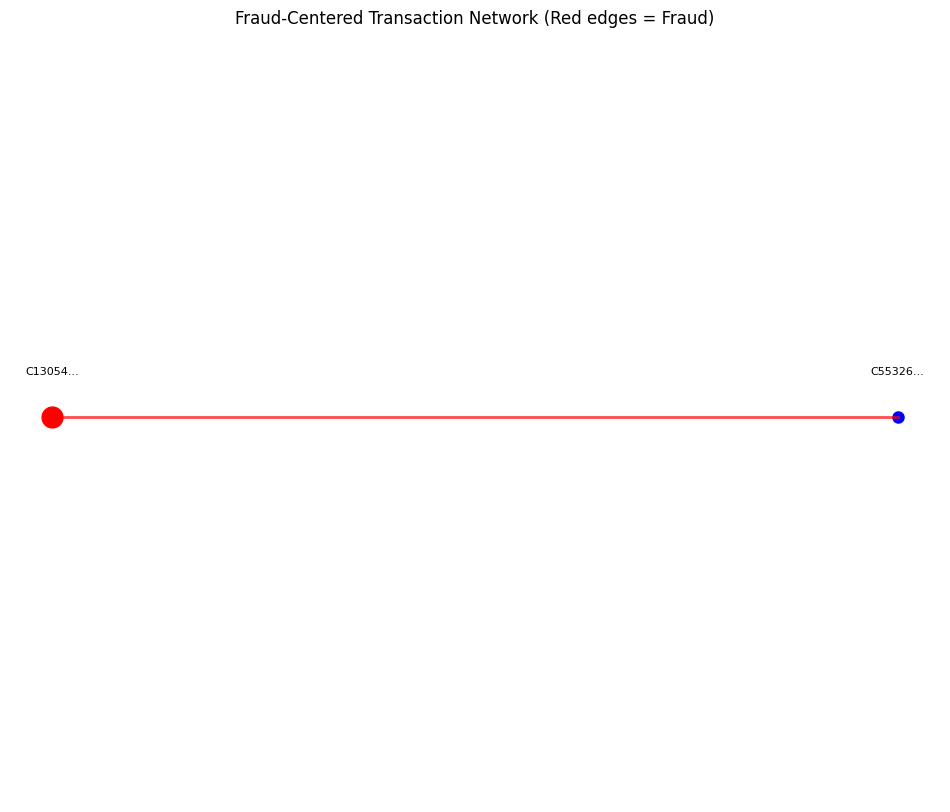

In [14]:
# Visualization focused on fraud
from pyspark.sql.functions import col
import matplotlib.pyplot as plt
import math

# Find accounts involved in fraud
fraud_edges = g.edges.filter(col("isFraud") == 1)
fraud_accounts_src = fraud_edges.select("src").distinct()
fraud_accounts_dst = fraud_edges.select("dst").distinct()

# Take one fraud account as center 
# (preferring one with both incoming and outgoing fraudulent transactions if possible)
fraud_center = None

# Try to find an account that's both a source and destination in fraud
fraud_both = fraud_accounts_src.join(
    fraud_accounts_dst,
    fraud_accounts_src.src == fraud_accounts_dst.dst
).limit(1)

if fraud_both.count() > 0:
    # Found an account that's both source and destination in fraud
    fraud_center = fraud_both.first().src
else:
    # Just take any account involved in fraud
    if fraud_accounts_src.count() > 0:
        fraud_center = fraud_accounts_src.first().src
    else:
        fraud_center = fraud_accounts_dst.first().dst

print(f"Selected fraud-involved center: {fraud_center}")

# Get neighbors of this account (both incoming and outgoing)
out_neighbors = g.edges.filter(col("src") == fraud_center).limit(10)
in_neighbors = g.edges.filter(col("dst") == fraud_center).limit(10)

out_neighbor_ids = [row.dst for row in out_neighbors.collect()]
in_neighbor_ids = [row.src for row in in_neighbors.collect()]
neighbor_ids = list(set(out_neighbor_ids + in_neighbor_ids))

print(f"Found {len(neighbor_ids)} neighbors")

# Add the central vertex
all_vertices = [fraud_center] + neighbor_ids

# Get all edges between these vertices
sampled_edges = g.edges.filter(
    (col("src").isin(all_vertices)) & 
    (col("dst").isin(all_vertices))
).collect()

print(f"Number of edges between these vertices: {len(sampled_edges)}")
print(f"Number of fraud edges: {sum(1 for e in sampled_edges if e.isFraud == 1)}")

# Create visualization
plt.figure(figsize=(12, 10))

# Position the central node in the middle
positions = {fraud_center: (0, 0)}

# Position neighbors in a circle around the central node
num_neighbors = len(neighbor_ids)
if num_neighbors > 0:
    for i, vertex_id in enumerate(neighbor_ids):
        angle = 2 * math.pi * i / num_neighbors
        positions[vertex_id] = (math.cos(angle), math.sin(angle))

    # Draw vertices
    for vertex_id, (x, y) in positions.items():
        # Make the central node larger and red to indicate fraud involvement
        size = 15 if vertex_id == fraud_center else 8
        color = 'red' if vertex_id == fraud_center else 'blue'
        plt.plot(x, y, 'o', markersize=size, color=color)
        
        # Add vertex labels with shorter IDs
        short_id = vertex_id[:6] + "..." if len(vertex_id) > 6 else vertex_id
        plt.text(x, y+0.05, short_id, fontsize=8, ha='center')

    # Draw edges with increased visibility 
    for edge in sampled_edges:
        if edge.src in positions and edge.dst in positions:
            x1, y1 = positions[edge.src]
            x2, y2 = positions[edge.dst]
            color = 'red' if edge.isFraud == 1 else 'gray'
            # Thicker lines for fraud
            width = 2.0 if edge.isFraud == 1 else 0.7
            plt.plot([x1, x2], [y1, y2], color=color, linewidth=width, alpha=0.7)

    plt.title("Fraud-Centered Transaction Network (Red edges = Fraud)")
    plt.axis('equal')
    plt.axis('off')
    plt.show()
else:
    print("No neighbors found to visualize. The graph may be disconnected.")

In [15]:
df.show()

+----+--------+----------+-----------+-------------+--------------+-----------+--------------+--------------+-------+--------------+--------------+-----------------+-------------------+-------------------+--------------------+----------------------+----------------------+
|step|    type|    amount|   nameOrig|oldbalanceOrg|newbalanceOrig|   nameDest|oldbalanceDest|newbalanceDest|isFraud|isFlaggedFraud|is_to_merchant|is_high_risk_type|        sender_diff|      receiver_diff|sender_balance_error|receiver_balance_error|dest_appears_as_origin|
+----+--------+----------+-----------+-------------+--------------+-----------+--------------+--------------+-------+--------------+--------------+-----------------+-------------------+-------------------+--------------------+----------------------+----------------------+
| 451|TRANSFER|1084324.81|C1173664118|          0.0|           0.0|C1026756725|    3602262.67|    4686587.48|      0|             0|             0|                1|                

In [16]:
# Drop unnecessary columns for ML training
df_ml = df.drop("nameOrig", "nameDest", "step")

# Check the resulting schema
df_ml.printSchema()

# Show a sample of the cleaned data
df_ml.show(5)

root
 |-- type: string (nullable = true)
 |-- amount: double (nullable = true)
 |-- oldbalanceOrg: double (nullable = true)
 |-- newbalanceOrig: double (nullable = true)
 |-- oldbalanceDest: double (nullable = false)
 |-- newbalanceDest: double (nullable = false)
 |-- isFraud: integer (nullable = true)
 |-- isFlaggedFraud: integer (nullable = true)
 |-- is_to_merchant: integer (nullable = false)
 |-- is_high_risk_type: integer (nullable = false)
 |-- sender_diff: double (nullable = true)
 |-- receiver_diff: double (nullable = false)
 |-- sender_balance_error: double (nullable = true)
 |-- receiver_balance_error: double (nullable = true)
 |-- dest_appears_as_origin: integer (nullable = false)

+--------+---------+-------------+--------------+--------------+--------------+-------+--------------+--------------+-----------------+------------------+-------------------+--------------------+----------------------+----------------------+
|    type|   amount|oldbalanceOrg|newbalanceOrig|oldbala

In [17]:
from pyspark.ml.feature import OneHotEncoder, StringIndexer, VectorAssembler, StandardScaler
from pyspark.ml import Pipeline

# 1. Process the categorical 'type' column (keep your existing code)
indexer = StringIndexer(inputCol="type", outputCol="typeIndex")
encoder = OneHotEncoder(inputCol="typeIndex", outputCol="typeVec")

# 2. Process original numeric features (keep your existing code)
original_numeric_cols = ["amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest"]
assembler_original = VectorAssembler(inputCols=original_numeric_cols, outputCol="features_raw")
scaler = StandardScaler(inputCol="features_raw", outputCol="scaledFeatures", withStd=True, withMean=False)

# 3. Process the engineered numeric features
engineered_numeric_cols = ["sender_diff", "receiver_diff", 
                          "sender_balance_error", "receiver_balance_error"]
assembler_engineered = VectorAssembler(inputCols=engineered_numeric_cols, 
                                       outputCol="engineered_features_raw",
                                       handleInvalid="skip")
scaler_engineered = StandardScaler(inputCol="engineered_features_raw", 
                                  outputCol="scaledEngineeredFeatures", 
                                  withStd=True, withMean=False)

# 4. Handle binary features - no transformation needed as they're already 0/1
binary_cols = ["is_to_merchant", "is_high_risk_type", "dest_appears_as_origin"]

# 5. Create the full pipeline
pipeline = Pipeline(stages=[
    indexer, 
    encoder, 
    assembler_original, 
    scaler,
    assembler_engineered,
    scaler_engineered
])

# 6. Fit and transform data
processed_model = pipeline.fit(df_ml)  # Use df_ml which has redundant columns dropped
processed_df = processed_model.transform(df_ml)

# 7. Create the final feature vector combining everything
final_cols = [
    "typeVec",                   # One-hot encoded type
    "scaledFeatures",            # Scaled original numeric features
    "scaledEngineeredFeatures",  # Scaled engineered numeric features
] + binary_cols                  # Binary features (already 0/1)

final_assembler = VectorAssembler(
    inputCols=final_cols,
    outputCol="features",
    handleInvalid="skip"
)

# 8. Create the final dataframe with all features assembled
final_df = final_assembler.transform(processed_df)

# Verify results
final_df.select("features", "isFraud").show(5, truncate=False)

+----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+-------+
|features                                                                                                                                                                                                        |isFraud|
+----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+-------+
|[0.0,0.0,1.0,0.0,0.14808094903892743,0.4105173298173826,0.4360712788148794,0.04808688994594186,0.020150653710397027,0.6097783413233867,-0.10999581897570013,-0.2947987543909813,-0.4050467662051597,0.0,0.0,0.0]|0      |
|(16,[2,4,5,6,9,11,12],[1.0,0.17970610376064813,0.0039051427725558404,0.04096922806819587,0.7400066692444663,-0.357757941780

In [18]:
final_df = final_df.select("features", "isFraud")

In [19]:
# Split and balance the dataset(Semi-Supervised Split)
from pyspark.sql.functions import rand

# Step 1: Split into training and testing sets (e.g. 80% train, 20% test)
train_df, test_df = final_df.randomSplit([0.8, 0.2], seed=42)


In [20]:

# Step 2: Apply the semi-supervised split approach to the **train set** only
# Separate fraud and non-fraud transactions in the train set
fraud_train = train_df.filter(train_df['isFraud'] == 1)
nonfraud_train = train_df.filter(train_df['isFraud'] == 0)


In [21]:

# Sample 1000 fraud and 1000 non-fraud cases for the labeled dataset
fraud_train_sample = fraud_train.limit(1000)
nonfraud_train_sample = nonfraud_train.limit(1000)


In [22]:
# Combine the labeled data (1000 fraud and 1000 non-fraud)
labeled_train = fraud_train_sample.union(nonfraud_train_sample).orderBy(rand())
# Remove labeled data from the original train set
train_pool_remaining = train_df.subtract(labeled_train)

In [23]:
# Rebalance the remaining data
fraud_remaining = train_pool_remaining.filter(train_pool_remaining['isFraud'] == 1)
nonfraud_remaining = train_pool_remaining.filter(train_pool_remaining['isFraud'] == 0)

In [24]:
# Desired fraud-to-non-fraud ratio for rebalancing
desired_ratio = 773
fraud_train_count = fraud_remaining.count()
target_nonfraud_count = fraud_train_count * desired_ratio
nonfraud_balanced = nonfraud_remaining.limit(target_nonfraud_count)

In [25]:
# Combine the rebalanced data
unlabeled_train_rebalanced = fraud_remaining.union(nonfraud_balanced).orderBy(rand())
#now we have 50/50 dataset named labeled_train
#and another dataset 1:773(real ratio)fraud:non #named unlabeled_train_rebalanced

In [39]:
# Compute class weights inversely proportional to class frequencies
from pyspark.sql.functions import count, when, lit
from pyspark.ml.classification import LogisticRegression
# Get class counts
class_counts = train_df.groupBy("isFraud").count().collect()
fraud_count = [row["count"] for row in class_counts if row["isFraud"] == 1.0][0]
nonfraud_count = [row["count"] for row in class_counts if row["isFraud"] == 0.0][0]
total = fraud_count + nonfraud_count

# Set weights inversely proportional to frequency
weights = {0.0: total/(2*nonfraud_count), 1.0: total/(2*fraud_count)}
print(f"Class weights: {weights}")
# Apply weights
weighted_lr = LogisticRegression(
    featuresCol="features",
    labelCol="isFraud",
    maxIter=10,
    regParam=0.1,
    elasticNetParam=0.0,
    weightCol="weight",  # Add weight column
    standardization=False,
    threshold=0.49
)

# Create weight column
weighted_train = train_df.withColumn(
    "weight", 
    when(col("isFraud") == 1.0, lit(weights[1.0])).otherwise(lit(weights[0.0]))
)

Class weights: {0.0: 0.5006483213266545, 1.0: 386.11125436068556}


In [ ]:
#drop variabl

In [ ]:
weighted_model = weighted_lr.fit(weighted_train)

In [42]:
initial_predictions = weighted_model.transform(test_df)

In [ ]:
# 2. Evaluate the initial model on test data
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator

# Make predictions on test data


# Calculate evaluation metrics
binary_evaluator = BinaryClassificationEvaluator(
    labelCol="isFraud", 
    rawPredictionCol="rawPrediction",
    metricName="areaUnderPR"  # Area under Precision-Recall curve
)
pr_auc = binary_evaluator.evaluate(initial_predictions)

# Also calculate AUC-ROC
binary_evaluator.setMetricName("areaUnderROC")
roc_auc = binary_evaluator.evaluate(initial_predictions)

f1_evaluator = MulticlassClassificationEvaluator(
    labelCol="isFraud", 
    predictionCol="prediction", 
    metricName="f1"
)
f1 = f1_evaluator.evaluate(initial_predictions)

print("Initial Model Metrics:")
print(f"Area Under PR Curve: {pr_auc:.4f}")
print(f"Area Under ROC Curve: {roc_auc:.4f}")
print(f"F1 Score: {f1:.4f}")

Initial Model Metrics:
Area Under PR Curve: 0.3828
Area Under ROC Curve: 0.9811
F1 Score: 0.9902


In [43]:
# Count TP, FP, TN, FN
tp = initial_predictions.filter((col("prediction") == 1) & (col("isFraud") == 1)).count()
fp = initial_predictions.filter((col("prediction") == 1) & (col("isFraud") == 0)).count()
tn = initial_predictions.filter((col("prediction") == 0) & (col("isFraud") == 0)).count()
fn = initial_predictions.filter((col("prediction") == 0) & (col("isFraud") == 1)).count()

# Calculate additional fraud-specific metrics
fraud_precision = tp / (tp + fp) if (tp + fp) > 0 else 0
fraud_recall = tp / (tp + fn) if (tp + fn) > 0 else 0
fraud_specificity = tn / (tn + fp) if (tn + fp) > 0 else 0

print("\n===== Fraud-Specific Metrics =====")
print(f"Fraud Precision (TP/(TP+FP)):   {fraud_precision:.4f}")
print(f"Fraud Recall (TP/(TP+FN)):      {fraud_recall:.4f}")
print(f"Fraud Specificity (TN/(TN+FP)): {fraud_specificity:.4f}")
print(f"Fraud F1 Score: {2 * (fraud_precision * fraud_recall) / (fraud_precision + fraud_recall) if (fraud_precision + fraud_recall) > 0 else 0:.4f}")
print("\nConfusion Matrix:")
print(f"                   Predicted Fraud  Predicted Non-Fraud")
print(f"Actual Fraud       {tp:<15d}   {fn:<15d}")
print(f"Actual Non-Fraud   {fp:<15d}   {tn:<15d}")


===== Fraud-Specific Metrics =====
Fraud Precision (TP/(TP+FP)):   0.0594
Fraud Recall (TP/(TP+FN)):      0.8401
Fraud Specificity (TN/(TN+FP)): 0.9830
Fraud F1 Score: 0.1110

Confusion Matrix:
                   Predicted Fraud  Predicted Non-Fraud
Actual Fraud       1361              259            
Actual Non-Fraud   21548             1248189        


In [30]:
# Test different thresholds to find optimal precision-recall balance
thresholds = [0.6, 0.7, 0.8, 0.85, 0.9, 0.95]
results = []

for threshold in thresholds:
    # Apply new threshold
    weighted_model.setThreshold(threshold)
    
    # Get predictions with new threshold
    pred_df = weighted_model.transform(test_df)
    
    # Calculate metrics
    tp = pred_df.filter((col("prediction") == 1) & (col("isFraud") == 1)).count()
    fp = pred_df.filter((col("prediction") == 1) & (col("isFraud") == 0)).count()
    fn = pred_df.filter((col("prediction") == 0) & (col("isFraud") == 1)).count()
    tn = pred_df.filter((col("prediction") == 0) & (col("isFraud") == 0)).count()
    
    # Calculate precision and recall
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
    
    results.append((threshold, precision, recall, f1))
    print(f"Threshold: {threshold:.2f} | Precision: {precision:.4f} | Recall: {recall:.4f} | F1: {f1:.4f}")

Threshold: 0.60 | Precision: 0.4540 | Recall: 0.5358 | F1: 0.4915
Threshold: 0.70 | Precision: 0.8292 | Recall: 0.4105 | F1: 0.5491
Threshold: 0.80 | Precision: 0.9576 | Recall: 0.3204 | F1: 0.4801


ERROR:root:KeyboardInterrupt while sending command.
Traceback (most recent call last):
  File "c:\Users\Ali\AppData\Local\Programs\Python\Python39\lib\site-packages\py4j\java_gateway.py", line 1038, in send_command
    response = connection.send_command(command)
  File "c:\Users\Ali\AppData\Local\Programs\Python\Python39\lib\site-packages\py4j\clientserver.py", line 511, in send_command
    answer = smart_decode(self.stream.readline()[:-1])
  File "c:\Users\Ali\AppData\Local\Programs\Python\Python39\lib\socket.py", line 704, in readinto
    return self._sock.recv_into(b)
KeyboardInterrupt


KeyboardInterrupt: 

In [ ]:
weighted_model.setThreshold(0.55)

# Get predictions with new threshold
pred_df = weighted_model.transform(test_df)

# Calculate metrics
tp = pred_df.filter((col("prediction") == 1) & (col("isFraud") == 1)).count()
fp = pred_df.filter((col("prediction") == 1) & (col("isFraud") == 0)).count()
fn = pred_df.filter((col("prediction") == 0) & (col("isFraud") == 1)).count()
tn = pred_df.filter((col("prediction") == 0) & (col("isFraud") == 0)).count()

# Calculate precision and recall
precision = tp / (tp + fp) if (tp + fp) > 0 else 0
recall = tp / (tp + fn) if (tp + fn) > 0 else 0
f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

results.append((threshold, precision, recall, f1))
print(f"Threshold: {threshold:.2f} | Precision: {precision:.4f} | Recall: {recall:.4f} | F1: {f1:.4f}")

Threshold: 0.95 | Precision: 0.2336 | Recall: 0.6395 | F1: 0.3422


In [ ]:
# Count TP, FP, TN, FN
tp = final_predictions.filter((col("prediction") == 1) & (col("isFraud") == 1)).count()
fp = final_predictions.filter((col("prediction") == 1) & (col("isFraud") == 0)).count()
tn = final_predictions.filter((col("prediction") == 0) & (col("isFraud") == 0)).count()
fn = final_predictions.filter((col("prediction") == 0) & (col("isFraud") == 1)).count()

# Calculate additional fraud-specific metrics
fraud_precision = tp / (tp + fp) if (tp + fp) > 0 else 0
fraud_recall = tp / (tp + fn) if (tp + fn) > 0 else 0
fraud_specificity = tn / (tn + fp) if (tn + fp) > 0 else 0

print("\n===== Fraud-Specific Metrics =====")
print(f"Fraud Precision (TP/(TP+FP)):   {fraud_precision:.4f}")
print(f"Fraud Recall (TP/(TP+FN)):      {fraud_recall:.4f}")
print(f"Fraud Specificity (TN/(TN+FP)): {fraud_specificity:.4f}")
print("\nConfusion Matrix:")
print(f"                   Predicted Fraud  Predicted Non-Fraud")
print(f"Actual Fraud       {tp:<15d}   {fn:<15d}")
print(f"Actual Non-Fraud   {fp:<15d}   {tn:<15d}")


===== Fraud-Specific Metrics =====
Fraud Precision (TP/(TP+FP)):   0.9144
Fraud Recall (TP/(TP+FN)):      0.2111
Fraud Specificity (TN/(TN+FP)): 1.0000

Confusion Matrix:
                   Predicted Fraud  Predicted Non-Fraud
Actual Fraud       342               1278           
Actual Non-Fraud   32                1269705        


In [44]:
from pyspark.ml.classification import GBTClassifier
from pyspark.sql.functions import when, col, lit
import math

# Define new precision-focused cost weights that work well with tree-based models
cost_weights = {0.0: 1.0, 1.0: 10.0}  # More balanced weights for tree models
print(f"GBT cost weights: {cost_weights}")

# Create training data with these weights
gbt_weighted_train = train_df.withColumn(
    "weight", 
    when(col("isFraud") == 1.0, lit(cost_weights[1.0]))
    .otherwise(lit(cost_weights[0.0]))
)

# Create GBT model (PySpark's equivalent to XGBoost)
gbt = GBTClassifier(
    featuresCol="features",
    labelCol="isFraud",
    weightCol="weight",
    maxIter=10,  # Number of trees
    maxDepth=5,  # Tree depth
    stepSize=0.1,  # Learning rate
    subsamplingRate=0.8,  # Similar to XGBoost's subsample
    minInstancesPerNode=5,  # Min samples for a leaf
    seed=42
)

# Train the model
print("Training GBT model...")
gbt_model = gbt.fit(gbt_weighted_train)
print("GBT model training complete")

# Make predictions
gbt_predictions = gbt_model.transform(test_df)

# Calculate metrics
tp = gbt_predictions.filter((col("prediction") == 1) & (col("isFraud") == 1)).count()
fp = gbt_predictions.filter((col("prediction") == 1) & (col("isFraud") == 0)).count()
tn = gbt_predictions.filter((col("prediction") == 0) & (col("isFraud") == 0)).count()
fn = gbt_predictions.filter((col("prediction") == 0) & (col("isFraud") == 1)).count()

precision = tp / (tp + fp) if (tp + fp) > 0 else 0
recall = tp / (tp + fn) if (tp + fn) > 0 else 0
f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

print("\n===== GBT Model Metrics =====")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")
print("\nConfusion Matrix:")
print(f"                   Predicted Fraud  Predicted Non-Fraud")
print(f"Actual Fraud       {tp:<15d}   {fn:<15d}")
print(f"Actual Non-Fraud   {fp:<15d}   {tn:<15d}")

# Feature importance from GBT
feature_importances = gbt_model.featureImportances.toArray()

GBT cost weights: {0.0: 1.0, 1.0: 10.0}
Training GBT model...
GBT model training complete

===== GBT Model Metrics =====
Precision: 0.9975
Recall: 0.9951
F1 Score: 0.9963

Confusion Matrix:
                   Predicted Fraud  Predicted Non-Fraud
Actual Fraud       1612              8              
Actual Non-Fraud   4                 1269733        


Random Forest weights: {0.0: 1.0, 1.0: 25.0}
Training Random Forest model...
Random Forest model training complete

===== Random Forest Model Metrics =====
Precision: 0.9988
Recall: 0.9944
F1 Score: 0.9966

Confusion Matrix:
                   Predicted Fraud  Predicted Non-Fraud
Actual Fraud       1611              9              
Actual Non-Fraud   2                 1269735        


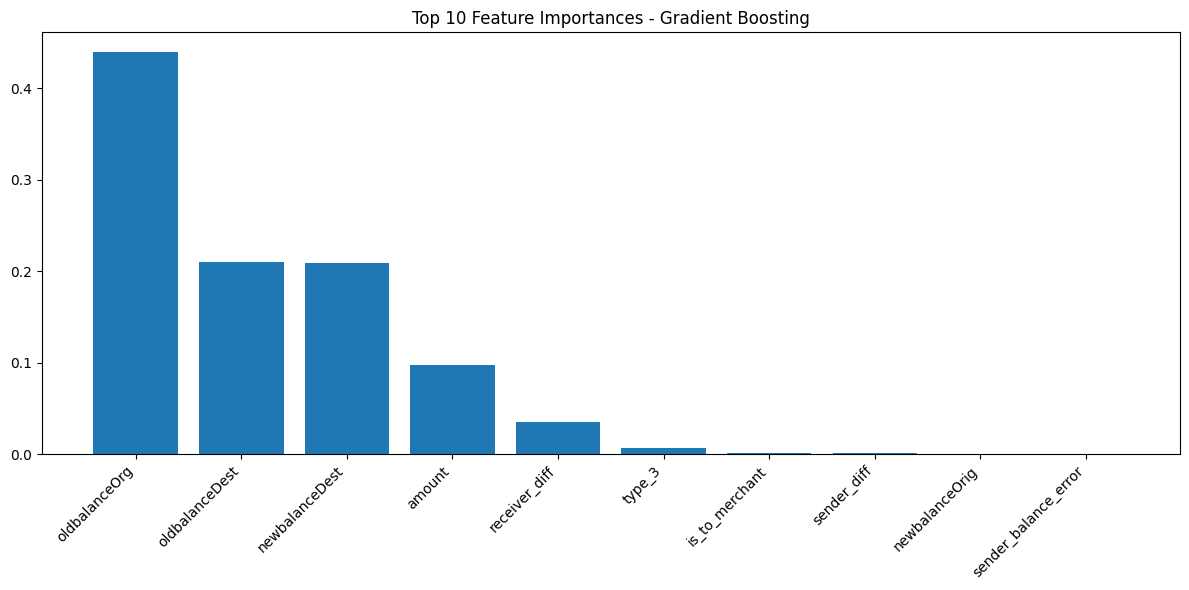

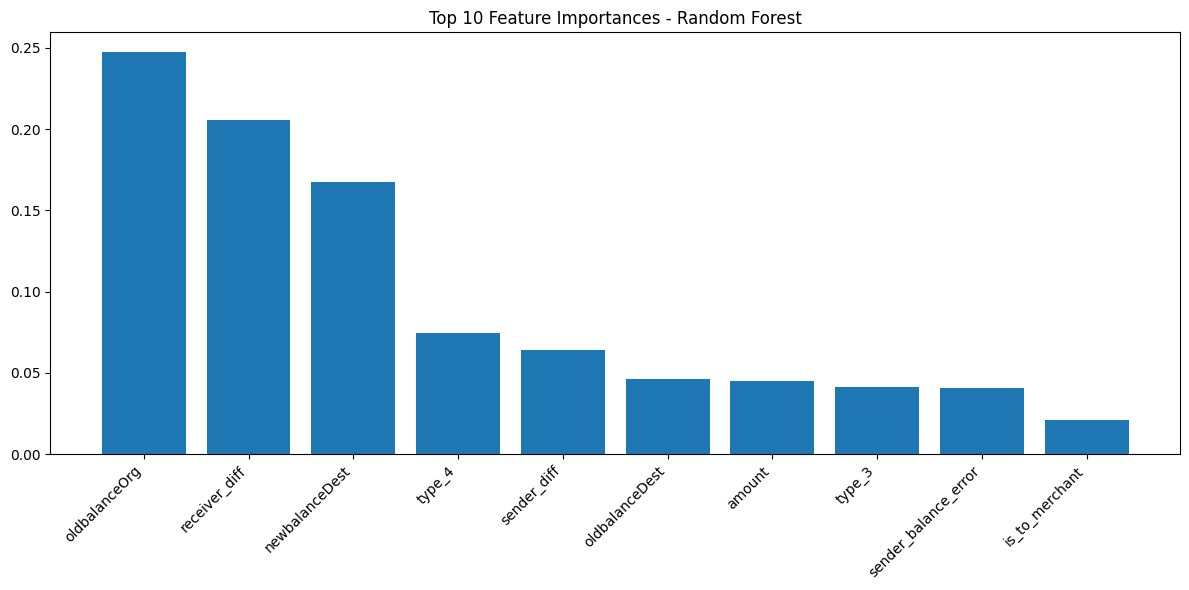

In [ ]:
from pyspark.ml.classification import RandomForestClassifier
import matplotlib.pyplot as plt
import numpy as np

# Define weights for Random Forest
rf_weights = {0.0: 1.0, 1.0: 25.0} 
print(f"Random Forest weights: {rf_weights}")

# Create training data with these weights
rf_weighted_train = train_df.withColumn(
    "weight", 
    when(col("isFraud") == 1.0, lit(rf_weights[1.0]))
    .otherwise(lit(rf_weights[0.0]))
)

# Create Random Forest model
rf = RandomForestClassifier(
    featuresCol="features",
    labelCol="isFraud",
    weightCol="weight",
    numTrees=100,  # More trees than GBT typically
    maxDepth=10,
    seed=42,
    bootstrap=True,
    subsamplingRate=0.8,  # 80% of data per tree
    featureSubsetStrategy="sqrt"  # Use sqrt(features) per split
)

# Train the model
print("Training Random Forest model...")
rf_model = rf.fit(rf_weighted_train)
print("Random Forest model training complete")

# Make predictions
rf_predictions = rf_model.transform(test_df)

# Calculate metrics
tp = rf_predictions.filter((col("prediction") == 1) & (col("isFraud") == 1)).count()
fp = rf_predictions.filter((col("prediction") == 1) & (col("isFraud") == 0)).count()
tn = rf_predictions.filter((col("prediction") == 0) & (col("isFraud") == 0)).count()
fn = rf_predictions.filter((col("prediction") == 0) & (col("isFraud") == 1)).count()

precision = tp / (tp + fp) if (tp + fp) > 0 else 0
recall = tp / (tp + fn) if (tp + fn) > 0 else 0
f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

print("\n===== Random Forest Model Metrics =====")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")
print("\nConfusion Matrix:")
print(f"                   Predicted Fraud  Predicted Non-Fraud")
print(f"Actual Fraud       {tp:<15d}   {fn:<15d}")
print(f"Actual Non-Fraud   {fp:<15d}   {tn:<15d}")



In [46]:
# Function to evaluate model performance
def evaluate_model(model, data, model_name):
    # Make predictions
    predictions = model.transform(data)
    
    # Calculate confusion matrix
    tp = predictions.filter((col("prediction") == 1) & (col("isFraud") == 1)).count()
    fp = predictions.filter((col("prediction") == 1) & (col("isFraud") == 0)).count()
    tn = predictions.filter((col("prediction") == 0) & (col("isFraud") == 0)).count()
    fn = predictions.filter((col("prediction") == 0) & (col("isFraud") == 1)).count()
    
    # Calculate metrics
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
    
    return {
        "Model": model_name,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "Specificity": specificity,
        "TP": tp,
        "FP": fp,
        "TN": tn,
        "FN": fn
    }

# Evaluate models on training data
print("===== MODEL EVALUATION ON TRAINING DATA =====\n")
models = [
    (weighted_model, "Logistic Regression"),
    (gbt_model, "Gradient Boosting"),
    (rf_model, "Random Forest")
]

# Print header
print(f"{'Model':<20} {'Precision':<10} {'Recall':<10} {'F1 Score':<10} {'Specificity':<10}")
print("-" * 60)

for model, name in models:
    results = evaluate_model(model, train_df, name)
    print(f"{name:<20} {results['Precision']:<10.4f} {results['Recall']:<10.4f} {results['F1 Score']:<10.4f} {results['Specificity']:<10.4f}")
    print(f"  Confusion Matrix: TP={results['TP']}, FP={results['FP']}, TN={results['TN']}, FN={results['FN']}")

===== MODEL EVALUATION ON TRAINING DATA =====

Model                Precision  Recall     F1 Score   Specificity
------------------------------------------------------------
Logistic Regression  0.0593     0.8251     0.1107     0.9830    
  Confusion Matrix: TP=5440, FP=86276, TN=4998394, FN=1153
Gradient Boosting    0.9968     0.9962     0.9965     1.0000    
  Confusion Matrix: TP=6568, FP=21, TN=5084649, FN=25
Random Forest        0.9983     0.9967     0.9975     1.0000    
  Confusion Matrix: TP=6571, FP=11, TN=5084659, FN=22


In [ ]:
# Evaluate models on test data
print("\n===== MODEL EVALUATION ON TEST DATA =====\n")

# Print header
print(f"{'Model':<20} {'Precision':<10} {'Recall':<10} {'F1 Score':<10} {'Specificity':<10}")
print("-" * 60)

for model, name in models:
    results = evaluate_model(model, test_df, name)
    print(f"{name:<20} {results['Precision']:<10.4f} {results['Recall']:<10.4f} {results['F1 Score']:<10.4f} {results['Specificity']:<10.4f}")
    print(f"  Confusion Matrix: TP={results['TP']}, FP={results['FP']}, TN={results['TN']}, FN={results['FN']}")

In [ ]:
# Evaluate models on the entire dataset
print("\n===== MODEL EVALUATION ON COMPLETE DATASET =====\n")

# Combine train and test datasets
whole_dataset = final_df

# Print header
print(f"{'Model':<20} {'Precision':<10} {'Recall':<10} {'F1 Score':<10} {'Specificity':<10}")
print("-" * 60)

for model, name in models:
    results = evaluate_model(model, whole_dataset, name)
    print(f"{name:<20} {results['Precision']:<10.4f} {results['Recall']:<10.4f} {results['F1 Score']:<10.4f} {results['Specificity']:<10.4f}")
    print(f"  Confusion Matrix: TP={results['TP']}, FP={results['FP']}, TN={results['TN']}, FN={results['FN']}")

# Calculate and show fraud distribution percentage
fraud_count = whole_dataset.filter(col("isFraud") == 1).count()
total_count = whole_dataset.count()
fraud_percentage = (fraud_count / total_count) * 100

print(f"\nFraud Distribution: {fraud_count:,} out of {total_count:,} transactions ({fraud_percentage:.4f}%)")


===== MODEL EVALUATION ON COMPLETE DATASET =====

Model                Precision  Recall     F1 Score   Specificity
------------------------------------------------------------


In [ ]:
# Feature importance from Random Forest
feature_importances = rf_model.featureImportances.toArray()

# Visualize feature importance for both models
def plot_feature_importance(model, model_name, feature_names, top_n=10):
    importances = model.featureImportances.toArray()
    indices = np.argsort(importances)[::-1][:top_n]
    
    plt.figure(figsize=(12, 6))
    plt.title(f'Top {top_n} Feature Importances - {model_name}')
    plt.bar(range(top_n), [importances[i] for i in indices])
    plt.xticks(range(top_n), [feature_names[i] for i in indices], rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

# Create feature names list (same as in your original code)
feature_names = []
feature_names += [f"type_{i}" for i in range(5)]  # Assuming 5 transaction types
feature_names += original_numeric_cols
feature_names += engineered_numeric_cols
feature_names += binary_cols
feature_names = feature_names[:len(gbt_model.featureImportances.toArray())]

# Plot feature importances
plot_feature_importance(gbt_model, "Gradient Boosting", feature_names)
plot_feature_importance(rf_model, "Random Forest", feature_names)

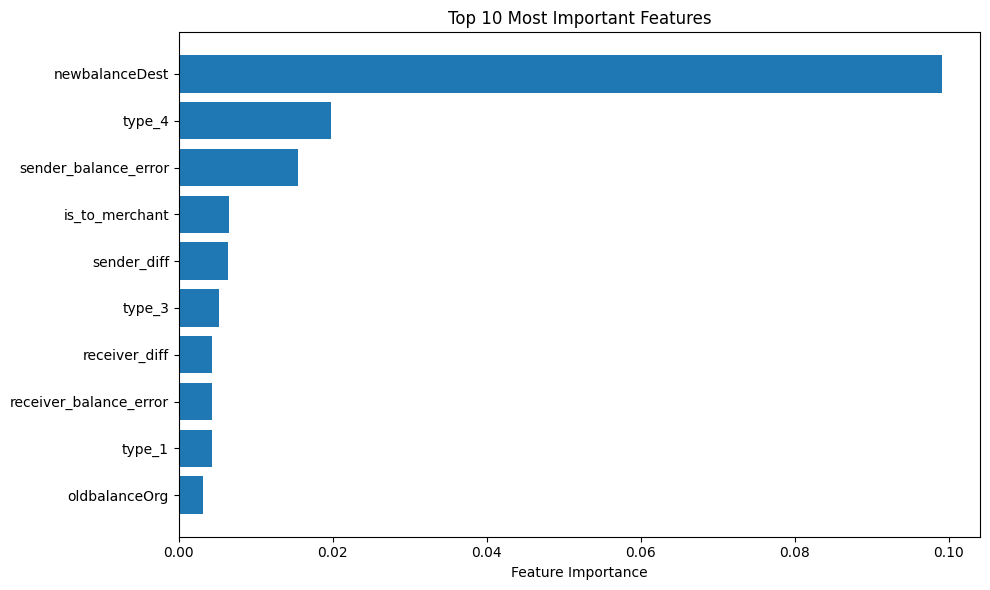

In [ ]:
# 6. Feature importance analysis without pandas
import numpy as np
import matplotlib.pyplot as plt

# Get feature importance from the coefficients
coefficients = final_model.coefficients.toArray()

# Create feature names list (approximation)
feature_names = []
feature_names += [f"type_{i}" for i in range(5)]  # Assuming 5 transaction types
feature_names += original_numeric_cols
feature_names += engineered_numeric_cols
feature_names += binary_cols

# Limit to the actual number of coefficients
feature_names = feature_names[:len(coefficients)]
importance_values = np.abs(coefficients)

# Sort by importance
sorted_indices = np.argsort(importance_values)[::-1]
top_indices = sorted_indices[:10]  # Get top 10

# Plot top features
plt.figure(figsize=(10, 6))
plt.barh([feature_names[i] for i in top_indices], 
         [importance_values[i] for i in top_indices])
plt.xlabel('Feature Importance')
plt.title('Top 10 Most Important Features')
plt.gca().invert_yaxis()  # Put highest values at the top
plt.tight_layout()
plt.show()

In [ ]:
# Save the initial model using Python serialization instead of Spark's native saving
import os
import pickle

# Create directory if it doesn't exist
model_dir = "models"
if not os.path.exists(model_dir):
    os.makedirs(model_dir)

# Save models using pickle (more Windows-friendly)
# Save initial model coefficients and metadata
initial_model_metadata = {
    'coefficients': initial_model.coefficients.toArray(),
    'intercept': initial_model.intercept,
    'numFeatures': initial_model.numFeatures,
    'numClasses': initial_model.numClasses
}
initial_model_path = os.path.join(model_dir, "fraud_detection_initial_model.pkl")
with open(initial_model_path, 'wb') as f:
    pickle.dump(initial_model_metadata, f)
print(f"Initial model saved to: {initial_model_path}")

# Save final model coefficients and metadata
final_model_metadata = {
    'coefficients': final_model.coefficients.toArray(),
    'intercept': final_model.intercept,
    'numFeatures': final_model.numFeatures,
    'numClasses': final_model.numClasses
}
final_model_path = os.path.join(model_dir, "fraud_detection_final_model.pkl")
with open(final_model_path, 'wb') as f:
    pickle.dump(final_model_metadata, f)
print(f"Final model saved to: {final_model_path}")

# For the pipeline, save important pipeline parameters
pipeline_metadata = {
    'stages': [str(stage) for stage in processed_model.stages],
    'categorical_cols': ['type'],
    'numeric_cols': original_numeric_cols,
    'engineered_cols': engineered_numeric_cols,
    'binary_cols': binary_cols
}
pipeline_path = os.path.join(model_dir, "fraud_detection_pipeline.pkl")
with open(pipeline_path, 'wb') as f:
    pickle.dump(pipeline_metadata, f)
print(f"Feature processing pipeline metadata saved to: {pipeline_path}")

Initial model saved to: models\fraud_detection_initial_model.pkl
Final model saved to: models\fraud_detection_final_model.pkl
Feature processing pipeline metadata saved to: models\fraud_detection_pipeline.pkl


In [ ]:
# 1. Train initial model on the balanced dataset
# Create logistic regression with appropriate hyperparameters for imbalanced data
# lr = LogisticRegression(
#     featuresCol="features",
#     labelCol="isFraud",
#     maxIter=10,
#     regParam=0.1,      # L2 regularization
#     elasticNetParam=0.0,  # L2 regularization (0.0 = L2, 1.0 = L1)
#     threshold=0.5,  # Adjust threshold for fraud detection
#     standardization=False  # Already standardized features
# )

In [ ]:
# print(f"Labeled balanced training set: {labeled_train.count()} rows")
# print(f"Unlabeled data (realistic ratio): {unlabeled_train_rebalanced.count()} rows")
# print(f"Test data: {test_df.count()} rows")

In [ ]:
# labeled_train.show(5)

In [ ]:
# Train initial model on balanced dataset
# initial_model = lr.fit(labeled_train)

In [ ]:
# # 3. Semi-supervised approach: Use high-confidence predictions to augment training data
# from pyspark.sql.functions import col, when, udf
# from pyspark.sql.types import DoubleType

# # Create UDFs to extract probabilities from the vector
# @udf(returnType=DoubleType())
# def extract_fraud_prob(v):
#     return float(v[1])  # Get probability for class 1 (fraud)

# @udf(returnType=DoubleType())
# def extract_nonfraud_prob(v):
#     return float(v[0])  # Get probability for class 0 (non-fraud)
# # Add memory cleanup between major operations
# spark.catalog.clearCache()
# # Sample a smaller portion of unlabeled data to start with
# unlabeled_sample = unlabeled_train_rebalanced.limit(50000)  # Start with smaller number

# # Then apply model to this smaller sample
# unlabeled_with_predictions = initial_model.transform(unlabeled_sample)
# spark.catalog.clearCache()  
# # Continue with existing code on the smaller sample...
# unlabeled_with_probs = unlabeled_with_predictions.withColumn(
#     "prob_fraud", extract_fraud_prob(col("probability"))
# ).withColumn(
#     "prob_nonfraud", extract_nonfraud_prob(col("probability"))
# )

# # Select high-confidence predictions
# # For fraud (positive class):
# high_conf_fraud = unlabeled_with_probs.filter(
#     (col("prediction") == 1.0) & (col("prob_fraud") > 0.95)
# )

# # For non-fraud (negative class):
# high_conf_nonfraud = unlabeled_with_probs.filter(
#     (col("prediction") == 0.0) & (col("prob_nonfraud") > 0.95)
# )

# # Combine with original labeled data (pseudo-labeling)
# augmented_train = labeled_train.union(
#     high_conf_fraud.select(labeled_train.columns)
# ).union(
#     high_conf_nonfraud.select(labeled_train.columns)
# )

In [ ]:
# augmented_train_sample = augmented_train.limit(1000) 
# augmented_train_sample.show(5, truncate=False)

In [ ]:
# # 4. Train final model on augmented dataset
# final_model = lr.fit(unlabeled_train_rebalanced)
# # 5. Evaluate on test set
# final_predictions = final_model.transform(test_df)

In [ ]:
# final_predictions2 = initial_model.transform(test_df)

In [ ]:
# from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator

# # Make predictions if you haven't already
# final_predictions = final_model.transform(test_df)

# # Binary Classification Metrics (ROC, PR curves)
# binary_eval = BinaryClassificationEvaluator(labelCol="isFraud", rawPredictionCol="rawPrediction")
# roc_auc = binary_eval.setMetricName("areaUnderROC").evaluate(final_predictions2)
# pr_auc = binary_eval.setMetricName("areaUnderPR").evaluate(final_predictions2)

# # Multi-class metrics (Accuracy, Precision, Recall, F1)
# multi_eval = MulticlassClassificationEvaluator(labelCol="isFraud", predictionCol="prediction")

# accuracy = multi_eval.setMetricName("accuracy").evaluate(final_predictions2)
# precision = multi_eval.setMetricName("weightedPrecision").evaluate(final_predictions2)
# recall = multi_eval.setMetricName("weightedRecall").evaluate(final_predictions2)
# f1 = multi_eval.setMetricName("f1").evaluate(final_predictions2)

# # Print comprehensive results
# print("\n===== Fraud Detection Model Evaluation =====")
# print(f"Accuracy:          {accuracy:.4f}")
# print(f"Precision:         {precision:.4f}")
# print(f"Recall:            {recall:.4f}")
# print(f"F1 Score:          {f1:.4f}")
# print(f"Area Under ROC:    {roc_auc:.4f}")
# print(f"Area Under PR:     {pr_auc:.4f}")
